# Controllable English → Hindi translation with QLoRA
### Fine-tuning Qwen3-1.7B (4-bit) on semantically filtered data, with an ablation, numeral control and quality-aware decoding

**One model, one method:** `Qwen/Qwen3-1.7B-Base` fine-tuned with **QLoRA** (frozen 4-bit NF4 base + trainable LoRA adapters).

What makes this more than a standard fine-tuning notebook:

| # | Part | Question it answers |
|---|---|---|
| 1 | **Two-stage data cleaning**: rule filters, then **LaBSE semantic filtering** (cosine ≥ 0.80, the IndicTrans2 threshold) | How noisy is the IITB corpus really? |
| 2 | **Ablation**: same model, same size, rules-only data vs rules + LaBSE data | Does semantic filtering actually help a QLoRA-tuned LLM? |
| 3 | **Controllable output**: a `Numerals:` tag in the prompt switches 2024 ↔ २०२४ | Can one adapter learn a product-style control? |
| 4 | **India-specific evaluation**: FLORES+, IN22-Gen, IN22-Conv, IITB test; BLEU, chrF++, number match, COMET | How good is it, on benchmarks MT teams use? |
| 5 | **Quality-aware decoding**: sample candidates, pick by MBR (chrF) or by LaBSE quality estimation | Can decoding buy quality without retraining? |
| 6 | **Staged inference pipeline** that emits step events + a confidence score | The backbone for the web demo's step tracker |

**Kaggle settings (right sidebar):** Accelerator = **GPU T4 x2** (one GPU is used; not P100), Internet = **On**.
Optional but recommended: accept the terms of `openlanguagedata/flores_plus` on Hugging Face and add your token as a Kaggle secret named `HF_TOKEN`.

Run with **Save Version → Save & Run All (Commit)**. Expected total with the default settings: about 8–9 hours (extrapolated from a 2,000-pair dry run on a T4), plus about 45 minutes if FLORES+ loads. Kaggle's limit is 12 hours.

In [44]:
!pip install -q -U "transformers==5.23.0" "peft==0.21.3" "accelerate>=1.10" "bitsandbytes>=0.46" "sacrebleu==2.6.0" "datasets>=3.0" sentencepiece tabulate
# Kaggle ships an old torchao that makes peft raise an ImportError; this notebook doesn't use torchao (4-bit comes from bitsandbytes)
!pip uninstall -y -q torchao

In [45]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import re, gc, sys, json, time, random, shutil, subprocess, unicodedata
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import sacrebleu
from tqdm.auto import tqdm
from datasets import load_dataset, Dataset

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)
SUMMARY = {}                                    # every headline number ends up here → summary.json
print("torch", torch.__version__, "|", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
assert DEVICE == "cuda", "No GPU found: set Accelerator to GPU T4 x2 in the right sidebar, then run again."

torch 2.11.0+cu130 | cuda Tesla T4


### Config
**Dry run (about 30–40 min):** `POOL_SIZE = 8_000`, `N_TRAIN = 2_000`, `EVAL_LIMIT = 100`, `RERANK_LIMIT = 40`.
Put the full values back for the numbers you report.

In [46]:
MODEL_ID        = "Qwen/Qwen3-1.7B-Base"              # the one model that is fine-tuned
LABSE_ID        = "setu4993/LaBSE"                    # sentence encoder for semantic filtering + quality estimation
REF_MODEL_ID    = "facebook/nllb-200-distilled-600M"  # reference system, inference only (not trained)

POOL_SIZE       = 120_000   # rule-clean pairs that get a LaBSE score
LABSE_THRESHOLD = 0.80      # keep pairs with cosine similarity >= this
N_TRAIN         = 30_000    # training pairs per arm

RUN_ABLATION    = True      # also train a rules-only adapter of the same size (doubles training time)
RUN_REFERENCE   = True      # score NLLB-600M zero-shot as an outside reference point
RUN_RERANK      = True      # quality-aware decoding experiment
RUN_COMET       = True      # COMET in an isolated environment at the very end (failure is harmless)

MAX_LEN   = 256             # max tokens per training example (longer ones are dropped, not truncated)
EPOCHS    = 1
LR        = 2e-4
BATCH     = 8
GRAD_ACC  = 4               # effective batch = 32
LORA_R    = 16
USE_FP16  = True            # if the training loss ever shows nan, set this to False (slower)
GEN_BS    = 32              # lower to 16 on CUDA out-of-memory

EVAL_LIMIT   = 1000         # max sentences per test set (None = everything)
RERANK_LIMIT = 300          # sentences used in the decoding experiment
N_CAND       = 6            # candidates per sentence (1 greedy + 5 sampled)

## 1. Load the IIT Bombay English–Hindi corpus
About 1.66M training pairs from many sources: news, government text, TED talks, but also software UI strings, dictionary entries and misaligned lines.

In [47]:
iitb = load_dataset("cfilt/iitb-english-hindi")
print(iitb)

def to_pairs_df(split):
    df = iitb[split].flatten().to_pandas()
    return df.rename(columns={"translation.en": "en", "translation.hi": "hi"})[["en", "hi"]]

train_raw, dev_raw, test_raw = to_pairs_df("train"), to_pairs_df("validation"), to_pairs_df("test")
print(f"train={len(train_raw):,}  dev={len(dev_raw):,}  test={len(test_raw):,}")
train_raw.sample(8, random_state=1)

DatasetDict({
    train: Dataset({
        features: ['translation'],
        num_rows: 1659083
    })
    validation: Dataset({
        features: ['translation'],
        num_rows: 520
    })
    test: Dataset({
        features: ['translation'],
        num_rows: 2507
    })
})
train=1,659,083  dev=520  test=2,507


,en,hi
354196,Thus they will admit their sin. So away with the inmates of the Blaze!,ग़रज़ वह अपने गुनाह का इक़रार कर लेंगे तो दोज़ख़ियों को ख़ुदा की रहमत से दूरी है
317455,Of Pharaoh and Thamood?,(यानि) फिरऔन व समूद की (ज़रूर पहुँची है)
1493901,"(1B) Where refund of any amount becomes due to the deductor in respect of any amount paid to the credit of the Central Government under Chapter XVII-B, such...","(1ख) जहां अध्याय 17ख के अधीन केंद्रीय सरकार के खाते में संदत्त किसी रकम के संबंध में किसी रकम का प्रतिदाय कटौतीकर्ता को देय हो जाता है, वहां ऐसा कटौतीकर्ता,..."
774805,protection,सिक्युरटी
43655,Content Box,विषयवस्तु बॉक्स
590141,If your family stayed in the UK,अगर आप का परिवार UK में रहा हो।
683924,according to the Wall Street Journal.,केथोलिक चर्च ने गत वर्ष 97 बिलियन डालर एकत्रित किये.
1298606,"In one case the Supreme Court has observed that in Litigation undertaken for the purpose of redressing public injury, enforcing public duty, pro - tecting s...","एक मामले में उच्चतम न्यायालय ने कहा है, लोक क्षति के निवारण, लोक कर्तव्य के प्रवर्तन, सामाजिक-सामूहिक विकीर्ण अधिकारों और हितों के संरक्षण अथवा लोकहित की रक..."


## 2. Cleaning stage 1: rule-based filters
Unicode NFC normalisation, length limits, length-ratio check, script checks, noise patterns (URLs, `%s`, `_` menu accelerators, HTML), untranslated copies, de-duplication. Every step logs how many rows survive.

In [48]:
def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    s = s.replace("​", "").replace("﻿", "")
    return re.sub(r"\s+", " ", s).strip()

BAD_PATTERN = r"https?://|www\.|\S+@\S+\.\S+|%[sdif]|&\s?[lg]t;|\s_|_\s|\(_|\$\{|\\[nt]|<[^>]+>"

def clean_pairs(df, min_words=4, max_en_words=60, max_hi_words=80):
    df = df.copy()
    df["en"], df["hi"] = df["en"].map(normalize), df["hi"].map(normalize)
    stats = {"raw": len(df)}

    en_w, hi_w = df["en"].str.split().str.len(), df["hi"].str.split().str.len()
    m = en_w.between(min_words, max_en_words) & hi_w.between(min_words, max_hi_words)
    stats["length_ok"] = int(m.sum())

    m &= (hi_w / en_w.clip(lower=1)).between(0.6, 2.2)
    stats["ratio_ok"] = int(m.sum())

    hi_dev, hi_lat = df["hi"].str.count(r"[ऀ-ॿ]"), df["hi"].str.count(r"[A-Za-z]")
    en_dev, en_lat = df["en"].str.count(r"[ऀ-ॿ]"), df["en"].str.count(r"[A-Za-z]")
    m &= (hi_dev / (hi_dev + hi_lat).clip(lower=1) > 0.9) & (en_dev == 0) & (en_lat > 0)
    stats["script_ok"] = int(m.sum())

    m &= ~df["en"].str.contains(BAD_PATTERN, regex=True) & ~df["hi"].str.contains(BAD_PATTERN, regex=True)
    m &= df["en"].str.lower() != df["hi"].str.lower()
    stats["noise_ok"] = int(m.sum())

    df = df[m].drop_duplicates("en").drop_duplicates("hi").reset_index(drop=True)
    stats["after_dedup"] = len(df)
    return df, stats

train_clean, clean_stats = clean_pairs(train_raw)
pd.Series(clean_stats).to_frame("rows_remaining")

,rows_remaining
raw,1659083
length_ok,1070440
ratio_ok,1039243
script_ok,1011935
noise_ok,1001508
after_dedup,699356


## 3. Test sets and decontamination
| Test set | Size | Domain | Access |
|---|---|---|---|
| FLORES+ devtest | 1,012 | Wikipedia-style | gated: accept terms + `HF_TOKEN` |
| IN22-Gen | 1,024 | India-centric, multi-domain | tried from two repos |
| IN22-Conv | 1,503 | everyday conversation | tried from two repos |
| IITB test | 2,507 | news | always available |

If Hugging Face shows an access form on `ai4bharat/IN22-Gen` or `ai4bharat/IN22-Conv`, accept it with the same account as your token.
Any set that can't be loaded is skipped with a message; the notebook carries on. Every training pair whose English side appears in a test or dev set is then removed (**leakage prevention**).

In [49]:
def norm_df(df):
    return pd.DataFrame({"en": df["en"].map(normalize), "hi": df["hi"].map(normalize)}).reset_index(drop=True)

HF_TOKEN = None
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

def load_flores():
    en = load_dataset("openlanguagedata/flores_plus", "eng_Latn", split="devtest", token=HF_TOKEN).to_pandas()
    hi = load_dataset("openlanguagedata/flores_plus", "hin_Deva", split="devtest", token=HF_TOKEN).to_pandas()
    fl = en[["id", "text"]].merge(hi[["id", "text"]], on="id", suffixes=("_en", "_hi")).sort_values("id")
    return norm_df(fl.rename(columns={"text_en": "en", "text_hi": "hi"}))

def load_in22(name):
    last = None
    for repo, cfg in [(f"ai4bharat/{name}", "eng_Latn-hin_Deva"), (f"mteb/{name}", None), (f"mteb/{name}", "eng_Latn-hin_Deva")]:
        try:
            ds = load_dataset(repo, cfg, token=HF_TOKEN) if cfg else load_dataset(repo, token=HF_TOKEN)
            df = ds[list(ds.keys())[0]].to_pandas()
            if {"sentence1", "sentence2"} <= set(df.columns):
                en_col, hi_col = "sentence1", "sentence2"
            else:
                en_col = next(c for c in df.columns if c.endswith("eng_Latn"))
                hi_col = next(c for c in df.columns if c.endswith("hin_Deva"))
            return norm_df(df.rename(columns={en_col: "en", hi_col: "hi"})[["en", "hi"]])
        except Exception as e:
            last = e
    raise RuntimeError(f"could not load {name}: {repr(last)[:200]}")

test_sets = {}
for key, loader in [("flores_devtest", load_flores),
                    ("in22_gen", lambda: load_in22("IN22-Gen")),
                    ("in22_conv", lambda: load_in22("IN22-Conv")),
                    ("iitb_test", lambda: norm_df(test_raw))]:
    try:
        df = loader()
        test_sets[key] = df[(df.en.str.len() > 0) & (df.hi.str.len() > 0)].reset_index(drop=True)
    except Exception as e:
        print(f"SKIPPED {key}: {repr(e)[:250]}")
dev_df = norm_df(dev_raw)

held_out_en = set(pd.concat([d["en"] for d in test_sets.values()] + [dev_df["en"]]))
before = len(train_clean)
train_clean = train_clean[~train_clean["en"].isin(held_out_en)].reset_index(drop=True)
clean_stats["after_decontamination"] = len(train_clean)
print(f"removed {before - len(train_clean)} training pairs that overlap with test/dev")

if EVAL_LIMIT:
    test_sets = {k: v.sample(n=min(EVAL_LIMIT, len(v)), random_state=SEED).reset_index(drop=True) for k, v in test_sets.items()}
for k, v in test_sets.items():
    print(f"{k}: {len(v)} sentences")
MAIN_SET = next(k for k in ["flores_devtest", "in22_gen", "iitb_test"] if k in test_sets)
print("main test set for analysis:", MAIN_SET)

SKIPPED flores_devtest: DatasetNotFoundError("Dataset 'openlanguagedata/flores_plus' is a gated dataset on the Hub. You must be authenticated to access it.")
removed 6 training pairs that overlap with test/dev
in22_gen: 1000 sentences
in22_conv: 1000 sentences
iitb_test: 1000 sentences
main test set for analysis: in22_gen


## 4. Cleaning stage 2: semantic filtering with LaBSE
Rule filters can't tell whether the Hindi actually *means* the same as the English. **LaBSE** embeds sentences from 109 languages into one space, so a correct translation pair has high cosine similarity and a misaligned pair has low similarity. IndicTrans2's training corpus was filtered the same way, at the same 0.80 threshold.

We score a random pool of rule-clean pairs, look at the distribution, and read the rejected pairs by hand.

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

embedding:   0%|          | 0/469 [00:00<?, ?it/s]

embedding:   0%|          | 0/469 [00:00<?, ?it/s]

scored 120,000 pairs in 2.0 min | pass rate at 0.8: 55.7%


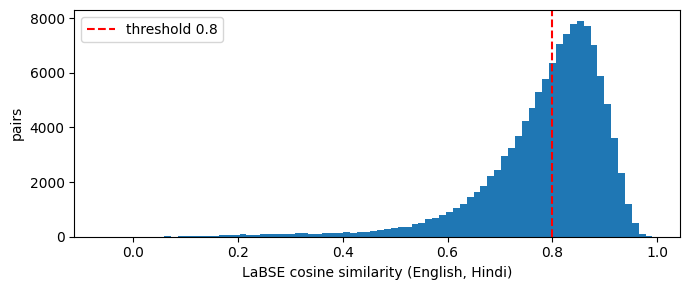

Lowest-scoring pairs that passed every rule filter (these are what LaBSE removes):


,labse,en,hi
12955,-0.059141,Because of continuous sneezing and coughing the rabbits rub their nose with the forelimbs.,पिस्सू लगने की स्थिति में उपचार उतना प्रभावी नहीं होता। भल
83851,-0.040121,"Do not be a sluggard, Take a step forward.",आयुध तो सभी विश्ष्ठि कार्यो में क्षत्रिय का मान्य प्राप्त प्रतीक बनता है।
38765,0.003982,It has been damaging to minority theatre everywhere.,वे प्रत्याशाएं झूठी सिद्ध नहीं हुई।
89806,0.014193,This type of all the activities are mostly influenced by the matters will take vise decisions.,इस तथ्य के भी कोई साक्ष्य नहीं हैं कि लॉर्ड विलियम बैन्टिक भारत के गवर्नर जनरल ने 1830 के दशक में ताजमहल को ध्वंस कर के उसका संगमर्मर नीलाम करने की योजना बन...
16885,0.018856,"Here and there, were seen the guests reclining on the grass, beneath blossomed magnolias and orange trees.","हमारा विश्वास हैं, फ्रंड ऑफ इंडिय ने टिप्पणी की, कि यह अफवाह बिल्कुल निराधार होगी।"
97580,0.020093,The treasure is at the Pyramids; “,"वैसे, अगर ले सको तो अपने निर्णय तुम खुद ही लेना।"
1268,0.021447,"Tor Luxury, originally of idea, and magnificence of execution, the fete was unequalled.",आज रात को 9.30 बजे वे एक और दवात में जा रहे हैं।
88658,0.022557,"it is known as selecting on a dependent variable,",क्योंकि आप पूरी कहानी पर नज़र ही नहीं डालते-
78824,0.023643,"Being costly, they are not able to compete in the markets of the country and abroad and lag behind.",इस स्थिति को बदलने के लिए फ्रेट कॉरिडोर की योजना बनाई गई थी।
12620,0.024866,Finishing later than late finish,गणना किया गया वेरिएंस एस्टीमेट


Borderline rejects, just under the threshold:


,labse,en,hi
29967,0.800000,"You feel deep, deep guilt.",आपको गहरा अपराध लगता है.
83015,0.799998,"Rather, this difficult time is also being used to advance research related to AYUSH in the country and the world.",बल्कि इस मुश्किल घड़ी का इस्तेमाल आयुष से जुड़ी रिसर्च को देश और दुनिया में आगे बढ़ाने के लिए किया जा रहा है।
20762,0.799998,It is a matter of satisfaction that the relations between our two countries continue to be marked by warmth and cordiality.,यह संतोष का विषय है कि हमारे दोनों देशों के बीच हार्दिक और सद्भावनापूर्ण संबंध रहे हैं।
7053,0.799997,He points out that many people can avoid illness simply by ensuring that the basement of dwellings is made impermeable to such gases.,उसने स्पष्ट किया कि तहखाने में बने आवासीय स्थलों को ऐसी गैसों से अभेद्य बना कर अनेक लोग रुग्णता से बच सकते हैं.
83260,0.799996,"As the name indicates, the caterpillars are covered with hair and are reddish - orange or brownish - orange in colour.",जैसा कि नाम से पता चलता है इन सूंडियों का शरीर हल्के रोयों बाल से ढ़का होता है और इनका रंग लाल-नारंगी या भूरा-नारंगी होता है।


In [50]:
from transformers import AutoTokenizer, AutoModel

labse_tok = AutoTokenizer.from_pretrained(LABSE_ID)
labse = AutoModel.from_pretrained(LABSE_ID).to(DEVICE).eval()
if DEVICE == "cuda":
    labse = labse.half()

@torch.no_grad()
def embed(texts, bs=256, max_length=128):
    """L2-normalised LaBSE sentence embeddings (pooler output), as a float32 numpy array."""
    texts = list(texts)
    order = np.argsort([-len(t) for t in texts])
    out = np.zeros((len(texts), labse.config.hidden_size), dtype=np.float32)
    for i in tqdm(range(0, len(texts), bs), desc="embedding", leave=False):
        idx = order[i:i + bs]
        enc = labse_tok([texts[j] for j in idx], return_tensors="pt", padding=True,
                        truncation=True, max_length=max_length).to(DEVICE)
        out[idx] = F.normalize(labse(**enc).pooler_output.float(), dim=-1).cpu().numpy()
    return out

def labse_similarity(a, b):
    return (embed(a) * embed(b)).sum(axis=1)

t0 = time.time()
pool = train_clean.sample(n=min(POOL_SIZE, len(train_clean)), random_state=SEED).reset_index(drop=True)
pool["labse"] = labse_similarity(pool["en"], pool["hi"])
pass_rate = float((pool.labse >= LABSE_THRESHOLD).mean())
print(f"scored {len(pool):,} pairs in {(time.time()-t0)/60:.1f} min | pass rate at {LABSE_THRESHOLD}: {pass_rate:.1%}")

plt.figure(figsize=(7, 3))
plt.hist(pool.labse, bins=80); plt.axvline(LABSE_THRESHOLD, color="red", ls="--", label=f"threshold {LABSE_THRESHOLD}")
plt.xlabel("LaBSE cosine similarity (English, Hindi)"); plt.ylabel("pairs"); plt.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/labse_hist.png", dpi=120); plt.show()

pd.set_option("display.max_colwidth", 160)
print("Lowest-scoring pairs that passed every rule filter (these are what LaBSE removes):")
display(pool.nsmallest(10, "labse")[["labse", "en", "hi"]])
print("Borderline rejects, just under the threshold:")
display(pool[pool.labse < LABSE_THRESHOLD].nlargest(5, "labse")[["labse", "en", "hi"]])

## 5. Build the two training arms and add numeral control
* **`rules_only`**: random sample of the rule-clean pool.
* **`rules_labse`**: random sample of the pairs that also pass LaBSE.

Same size, same seed, same hyperparameters: the only difference is the data filter, so any score gap is caused by it.

**Numeral control.** For pairs that contain digits, the Hindi side is rewritten to either international (2024) or Devanagari (२०२४) digits, and the prompt carries a matching `Numerals:` tag. Part of the digit pairs appear **twice**, once with each tag, so the model sees that the tag is the only difference (the dry run showed one random tag per pair was too weak a signal). Both arms get the same number of paired rows, so they stay the same size.

In [51]:
HOLDOUT = 500                                    # kept out of training; few-shot examples come from here
holdout, pool_tr = pool.tail(HOLDOUT), pool.iloc[:-HOLDOUT]
passed = pool_tr[pool_tr.labse >= LABSE_THRESHOLD]
n_arm = min(N_TRAIN, len(passed))
assert n_arm >= 500, "Too few pairs pass the LaBSE filter: raise POOL_SIZE or lower LABSE_THRESHOLD."

DEV_DIGITS, ASCII_DIGITS = "०१२३४५६७८९", "0123456789"
TO_ASCII, TO_DEV = str.maketrans(DEV_DIGITS, ASCII_DIGITS), str.maketrans(ASCII_DIGITS, DEV_DIGITS)

HAS_DIGIT = r"[0-9०-९]"

def add_numeral_control(df, n_pairs=0, seed=SEED):
    """Tag every row 'international' or 'native' and rewrite its Hindi digits to match.
    The first n_pairs rows that contain digits appear twice, once with each tag, so the tag is
    the only thing that differs: the clearest possible signal for the model to learn the control."""
    out = df.copy().reset_index(drop=True)
    has_digit = out["hi"].str.contains(HAS_DIGIT).to_numpy()
    native = has_digit & (np.random.default_rng(seed).random(len(out)) < 0.5)
    pair_idx = np.flatnonzero(has_digit)[:n_pairs]
    native[pair_idx] = False                                 # paired originals → international
    out["num"] = np.where(native, "native", "international")
    out["hi"] = [h.translate(TO_DEV) if n else h.translate(TO_ASCII) for h, n in zip(out["hi"], native)]
    twins = out.iloc[pair_idx].assign(num="native")
    twins["hi"] = twins["hi"].map(lambda h: h.translate(TO_DEV))
    return pd.concat([out, twins]).sample(frac=1, random_state=seed).reset_index(drop=True)

base = {"rules_labse": passed.sample(n=n_arm, random_state=SEED)}
if RUN_ABLATION:
    base["rules_only"] = pool_tr.sample(n=n_arm, random_state=SEED)
# same number of paired rows in every arm → both arms train on exactly the same number of examples
n_pairs = min(int(df["hi"].str.contains(HAS_DIGIT).sum()) for df in base.values())
ARMS = {name: add_numeral_control(df, n_pairs=n_pairs) for name, df in base.items()}

arm_stats = pd.DataFrame({name: {"pairs": len(df), "mean_labse": round(df.labse.mean(), 3),
                                 "share_below_threshold": round(float((df.labse < LABSE_THRESHOLD).mean()), 3),
                                 "share_with_digits": round(float(df.hi.str.contains(HAS_DIGIT).mean()), 3),
                                 "training_examples": len(ARMS[name])}
                          for name, df in base.items()}).T
display(arm_stats)
for name, df in ARMS.items():
    df.to_csv(f"{OUT_DIR}/train_{name}.csv", index=False)
dev_ctl = add_numeral_control(dev_df.assign(labse=np.nan))
SUMMARY["data"] = {**clean_stats, "pool_scored": len(pool), "labse_pass_rate": round(pass_rate, 4),
                   "train_pairs_per_arm": n_arm, "paired_numeral_rows": n_pairs}

,pairs,mean_labse,share_below_threshold,share_with_digits,training_examples
rules_labse,30000.0,0.862,0.00,0.204,34289.0
rules_only,30000.0,0.788,0.44,0.143,34289.0


## 6. Metrics
* **BLEU** (sacreBLEU): word n-gram overlap. The number everyone asks for.
* **chrF++**: character n-grams + word bigrams; more reliable for Hindi, where words inflect heavily.
* **Number match**: share of numbers (2+ digits) in the English source that appear in the output, in either digit script. A cheap check for a costly error type. It undercounts when a number is legitimately spelled out or converted (1 million → 10 लाख).
* **COMET**: neural metric, computed in the last section.

In [52]:
NUM_RE = re.compile(r"\d[\d,]*(?:\.\d+)?")

def numbers(text):
    found = [m.replace(",", "").rstrip(".") for m in NUM_RE.findall(str(text).translate(TO_ASCII))]
    return [n for n in found if len(n.replace(".", "")) >= 2]

def number_match(srcs, hyps):
    total = hit = 0
    for s, h in zip(srcs, hyps):
        want, got = numbers(s), set(numbers(h))
        total += len(want); hit += sum(n in got for n in want)
    return round(100 * hit / total, 1) if total else float("nan")

def score(hyps, refs):
    return {"BLEU": round(sacrebleu.corpus_bleu(hyps, [refs]).score, 2),
            "chrF++": round(sacrebleu.corpus_chrf(hyps, [refs], word_order=2).score, 2)}

RESULTS, PREDS = [], {}
def evaluate_system(name, translate_fn):
    for ts, df in test_sets.items():
        t0 = time.time()
        hyps = [normalize(h) for h in translate_fn(df["en"].tolist())]
        row = {"system": name, "test_set": ts, "n": len(df), **score(hyps, df["hi"].tolist()),
               "num_match": number_match(df["en"], hyps), "minutes": round((time.time() - t0) / 60, 1)}
        RESULTS.append(row); print(row)
        PREDS[(name, ts)] = pd.DataFrame({"en": df["en"], "ref": df["hi"], "hyp": hyps})
        PREDS[(name, ts)].to_csv(f"{OUT_DIR}/preds__{name}__{ts}.csv", index=False)
    pd.DataFrame(RESULTS).to_csv(f"{OUT_DIR}/results.csv", index=False)

def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

## 7. Reference point: NLLB-200 (600M), zero-shot
Not trained here. A dedicated translation model gives an honest outside reference: it shows how far a small general-purpose LLM with a few hours of QLoRA gets compared with a purpose-built MT system.

In [53]:
if RUN_REFERENCE:
    try:
        from transformers import AutoModelForSeq2SeqLM
        ref_tok = AutoTokenizer.from_pretrained(REF_MODEL_ID, src_lang="eng_Latn", tgt_lang="hin_Deva")
        ref_model = AutoModelForSeq2SeqLM.from_pretrained(REF_MODEL_ID, dtype=torch.float32).to(DEVICE).eval()

        @torch.no_grad()
        def nllb_translate(sents, bs=32):
            tgt_id = ref_tok.convert_tokens_to_ids("hin_Deva")
            order = np.argsort([-len(s) for s in sents]); out = [None] * len(sents)
            for i in tqdm(range(0, len(sents), bs), desc="translating", leave=False):
                idx = order[i:i + bs]
                enc = ref_tok([sents[j] for j in idx], return_tensors="pt", padding=True, truncation=True, max_length=256).to(DEVICE)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                    gen = ref_model.generate(**enc, forced_bos_token_id=tgt_id, num_beams=4, max_new_tokens=256)
                for j, text in zip(idx, ref_tok.batch_decode(gen, skip_special_tokens=True)):
                    out[j] = text
            return out

        evaluate_system("nllb600M_reference", nllb_translate)
        del ref_model
    except Exception as e:
        print("Reference system skipped:", repr(e)[:300])
    free_gpu()

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

translating:   0%|          | 0/32 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

{'system': 'nllb600M_reference', 'test_set': 'in22_gen', 'n': 1000, 'BLEU': 25.05, 'chrF++': 50.94, 'num_match': 98.1, 'minutes': 1.4}


translating:   0%|          | 0/32 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

{'system': 'nllb600M_reference', 'test_set': 'in22_conv', 'n': 1000, 'BLEU': 24.13, 'chrF++': 45.81, 'num_match': 96.7, 'minutes': 0.4}


translating:   0%|          | 0/32 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=256) and `max_length`(=200) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

{'system': 'nllb600M_reference', 'test_set': 'iitb_test', 'n': 1000, 'BLEU': 23.74, 'chrF++': 49.35, 'num_match': 99.2, 'minutes': 0.9}


## 8. Load Qwen3-1.7B in 4-bit; tokenizer fertility
**QLoRA** keeps the base weights frozen in 4-bit NF4 (with double quantisation) and trains only small LoRA matrices.

*Fertility* = tokens per word. A tokenizer that shreds Hindi into many pieces makes training and generation slower and needs longer sequences; it's the "tokenizer tax" Indian-language model builders talk about.

In [54]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token

bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                             bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)

def load_base():
    return AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_cfg,
                                                device_map={"": 0}, dtype=torch.float16)

model = load_base()
print(f"GPU memory with the 4-bit model loaded: {torch.cuda.memory_allocated()/1e9:.2f} GB")

sample = ARMS["rules_labse"].sample(min(2000, n_arm), random_state=0)
def fertility(texts):
    return sum(len(tok(t, add_special_tokens=False)["input_ids"]) for t in texts) / sum(len(t.split()) for t in texts)
SUMMARY["fertility"] = {"english": round(fertility(sample.en), 2), "hindi": round(fertility(sample.hi), 2)}
print("tokens per word:", SUMMARY["fertility"])

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

GPU memory with the 4-bit model loaded: 6.80 GB
tokens per word: {'english': 1.32, 'hindi': 4.94}


## 9. Prompt format, generation, and the 3-shot baseline
A base (non-chat) model doesn't follow instructions on its own, so the fair "before" number is **few-shot prompting** with three worked examples. After fine-tuning, the same prompt is used with **no** examples.

In [55]:
PROMPT = "Translate English to Hindi.\nNumerals: {num}\nEnglish: {en}\nHindi:"

shots = holdout[(holdout.labse >= LABSE_THRESHOLD) & holdout.en.str.split().str.len().between(8, 16)].head(3)
if len(shots) < 3:
    shots = holdout.nlargest(3, "labse")
FEW_SHOT = "".join(PROMPT.format(num="international", en=r.en) + " " + r.hi.translate(TO_ASCII) + "\n\n" for r in shots.itertuples())
print(FEW_SHOT)

@torch.no_grad()
def llm_generate(model, prompts, n=1, max_new_tokens=300, **sampling):
    """Returns n completions per prompt (first line only)."""
    tok.padding_side = "left"                              # decoder-only generation needs left padding
    enc = tok(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
    gen = model.generate(**enc, max_new_tokens=max_new_tokens, num_return_sequences=n,
                         no_repeat_ngram_size=12,     # stops loops like "ऑनलाइन ऑनलाइन ऑनलाइन…" (12 tokens ≈ 2–3 Hindi words)
                         stop_strings=["\n"], tokenizer=tok,
                         pad_token_id=tok.pad_token_id, eos_token_id=tok.eos_token_id,
                         **(sampling or {"do_sample": False, "num_beams": 1}))
    texts = tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    tok.padding_side = "right"
    texts = [t.strip().split("\n")[0].strip() for t in texts]
    return [texts[i * n:(i + 1) * n] for i in range(len(prompts))]

def llm_translate(model, sents, prefix="", num="international", bs=GEN_BS):
    model.eval()
    order = np.argsort([-len(s) for s in sents]); out = [None] * len(sents)
    for i in tqdm(range(0, len(sents), bs), desc="translating", leave=False):
        idx = order[i:i + bs]
        res = llm_generate(model, [prefix + PROMPT.format(num=num, en=sents[j]) for j in idx])
        for j, r in zip(idx, res):
            out[j] = r[0]
    return out

demo = ["The government has announced new measures to control air pollution in Delhi.",
        "The company sold 4,500 units in 2023 and expects to cross 12,000 by 2026.",
        "Please submit your assignment before Friday evening."]
for en, hi in zip(demo, llm_translate(model, demo, prefix=FEW_SHOT)):
    print(f"{en}\n  → {hi}\n")

Translate English to Hindi.
Numerals: international
English: Description: This is a sculpture of four armed Vishnu.
Hindi: विवरण: यह चार सशस्त्र विष्णु की मूर्ति है।

Translate English to Hindi.
Numerals: international
English: Shares should always be bought from the broker who is a licence holder.
Hindi: शेयर हमेशा अनुज्ञप्तिधारी दलाल से ही खरीदना चाहिए।

Translate English to Hindi.
Numerals: international
English: Third, wider cultural contacts and people - to - people exchanges.
Hindi: तृतीय: व्यापक सांस्कृतिक संपर्क और लोगों में आपसी आदान-प्रदान




translating:   0%|          | 0/1 [00:00<?, ?it/s]

The government has announced new measures to control air pollution in Delhi.
  → राज्यपाल ने दिल्ली में वायु प्रदूषण को नियंत्रित करने के लिए नई मापदंडों को घोषित किया है।

The company sold 4,500 units in 2023 and expects to cross 12,000 by 2026.
  → कंपनी ने 2023 में 4,500 विक्रय किए और 2026 तक 12,000 को पार करने के लिए उम्मीन है।

Please submit your assignment before Friday evening.
  → आपको अपने ऑनलाइन ऑनलाइन ऑनलिमिटेड ऑनलाइन ऑनलीमिटेड ऑनलिमिटेड आदेश देने के लिए अपने ऑनलाइट ऑनलाइट ऑनलिमिटेड एक्सेस ऑनलिमिटेड अपने ऑनलाइज़ ऑनलाइट ऑनलीमिटेड अपने ऑलिमिटेड ऑनलिमिडेड ऑनलिमिटेट ऑनलिमिटेड लिमिटेड ऑनलिंटेड ऑनलिमिटेल ऑनलिमिटेड विलिमिटेड ऑनलाईट ऑनलिमिटेड के लिए अपने स्पेशियल ऑनलाइट ऑनलेट ऑनलिम



In [56]:
evaluate_system("qwen_3shot_baseline", lambda s: llm_translate(model, s, prefix=FEW_SHOT))
del model; free_gpu()

translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_3shot_baseline', 'test_set': 'in22_gen', 'n': 1000, 'BLEU': 6.16, 'chrF++': 25.82, 'num_match': 71.6, 'minutes': 10.6}


translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_3shot_baseline', 'test_set': 'in22_conv', 'n': 1000, 'BLEU': 6.8, 'chrF++': 26.14, 'num_match': 80.0, 'minutes': 8.5}


translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_3shot_baseline', 'test_set': 'iitb_test', 'n': 1000, 'BLEU': 4.98, 'chrF++': 25.27, 'num_match': 70.2, 'minutes': 10.4}


## 10. QLoRA training
* Loss is computed **only on the Hindi answer** (prompt tokens are masked with `-100`).
* An end-of-text token is appended so the model learns to stop.
* Over-long examples are dropped instead of truncated, so the model never learns to stop mid-sentence.
* LoRA (r=16) on all attention and MLP projections; gradient checkpointing + paged 8-bit AdamW to fit a T4.

The base model is reloaded fresh for every arm, so the two runs can't influence each other.

In [57]:
from peft import prepare_model_for_kbit_training, LoraConfig, get_peft_model, TaskType
from transformers import Trainer, TrainingArguments, DataCollatorForSeq2Seq

def build_example(ex):
    p = tok(PROMPT.format(num=ex["num"], en=ex["en"]), add_special_tokens=False)["input_ids"]
    t = tok(" " + ex["hi"], add_special_tokens=False)["input_ids"] + [tok.eos_token_id]
    return {"input_ids": p + t, "attention_mask": [1] * (len(p) + len(t)),
            "labels": [-100] * len(p) + t, "n_tok": len(p) + len(t)}

def to_ds(df):
    ds = Dataset.from_pandas(df[["en", "hi", "num"]], preserve_index=False)
    ds = ds.map(build_example, remove_columns=ds.column_names)
    n0 = len(ds)
    ds = ds.filter(lambda x: x["n_tok"] <= MAX_LEN).remove_columns("n_tok")
    print(f"  kept {len(ds)}/{n0} examples (≤ {MAX_LEN} tokens)")
    return ds

dev_ds = to_ds(dev_ctl)
TRAIN_LOGS = {}

def train_arm(name, df):
    print(f"\n===== training arm: {name} =====")
    train_ds = to_ds(df)
    model = prepare_model_for_kbit_training(load_base(), use_gradient_checkpointing=True,
                                            gradient_checkpointing_kwargs={"use_reentrant": False})
    model = get_peft_model(model, LoraConfig(
        task_type=TaskType.CAUSAL_LM, r=LORA_R, lora_alpha=2 * LORA_R, lora_dropout=0.05,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]))
    trainable, total = model.get_nb_trainable_parameters()   # counts packed 4-bit weights correctly
    model.print_trainable_parameters()

    steps_per_epoch = max(1, len(train_ds) // (BATCH * GRAD_ACC))
    eval_every = max(5, steps_per_epoch // 5)
    ckpt_dir = f"{OUT_DIR}/ckpt_{name}"
    args = TrainingArguments(
        output_dir=ckpt_dir, num_train_epochs=EPOCHS, learning_rate=LR,
        per_device_train_batch_size=BATCH, per_device_eval_batch_size=BATCH, gradient_accumulation_steps=GRAD_ACC,
        warmup_steps=0.03, lr_scheduler_type="cosine", weight_decay=0.0,
        optim="paged_adamw_8bit",
        fp16=(USE_FP16 and DEVICE == "cuda"),
        train_sampling_strategy="group_by_length",
        eval_strategy="steps", eval_steps=eval_every,
        save_strategy="steps", save_steps=eval_every, save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
        logging_steps=max(1, eval_every // 5), report_to="none", seed=SEED,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=dev_ds,
                      data_collator=DataCollatorForSeq2Seq(tok, label_pad_token_id=-100, pad_to_multiple_of=8))
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    trainer.train()
    minutes = (time.time() - t0) / 60
    TRAIN_LOGS[name] = trainer.state.log_history
    SUMMARY[f"train_{name}"] = {
        "examples": len(train_ds), "trainable_params_M": round(trainable / 1e6, 2),
        "trainable_pct": round(100 * trainable / total, 3), "minutes": round(minutes, 1),
        "peak_gpu_GB": round(torch.cuda.max_memory_allocated() / 1e9, 1) if DEVICE == "cuda" else None,
        "best_dev_loss": round(min([x["eval_loss"] for x in trainer.state.log_history if "eval_loss" in x], default=float("nan")), 4)}
    print(SUMMARY[f"train_{name}"])
    model.save_pretrained(f"{OUT_DIR}/adapter_{name}")
    shutil.rmtree(ckpt_dir, ignore_errors=True)           # keep the notebook output small
    model.config.use_cache = True
    del trainer; free_gpu()
    return model.eval()

Map:   0%|          | 0/520 [00:00<?, ? examples/s]

Filter:   0%|          | 0/520 [00:00<?, ? examples/s]

  kept 508/520 examples (≤ 256 tokens)


In [58]:
if RUN_ABLATION:
    model = train_arm("rules_only", ARMS["rules_only"])
    evaluate_system("qwen_qlora_rules_only", lambda s: llm_translate(model, s))
    del model; free_gpu()


===== training arm: rules_only =====


Map:   0%|          | 0/34289 [00:00<?, ? examples/s]

Filter:   0%|          | 0/34289 [00:00<?, ? examples/s]

  kept 32137/34289 examples (≤ 256 tokens)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


... (5 outputs left out)

translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_qlora_rules_only', 'test_set': 'in22_conv', 'n': 1000, 'BLEU': 12.06, 'chrF++': 32.77, 'num_match': 90.0, 'minutes': 6.0}


translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_qlora_rules_only', 'test_set': 'iitb_test', 'n': 1000, 'BLEU': 9.61, 'chrF++': 32.01, 'num_match': 87.6, 'minutes': 11.5}


In [59]:
model = train_arm("rules_labse", ARMS["rules_labse"])     # this is the final model
for en, hi in zip(demo, llm_translate(model, demo)):
    print(f"{en}\n  → {hi}\n")
evaluate_system("qwen_qlora_rules_labse", lambda s: llm_translate(model, s))


===== training arm: rules_labse =====


Map:   0%|          | 0/34289 [00:00<?, ? examples/s]

Filter:   0%|          | 0/34289 [00:00<?, ? examples/s]

  kept 31591/34289 examples (≤ 256 tokens)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


... (7 outputs left out)

translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_qlora_rules_labse', 'test_set': 'in22_conv', 'n': 1000, 'BLEU': 13.14, 'chrF++': 34.48, 'num_match': 91.7, 'minutes': 5.9}


translating:   0%|          | 0/32 [00:00<?, ?it/s]

{'system': 'qwen_qlora_rules_labse', 'test_set': 'iitb_test', 'n': 1000, 'BLEU': 10.95, 'chrF++': 34.25, 'num_match': 91.5, 'minutes': 10.5}


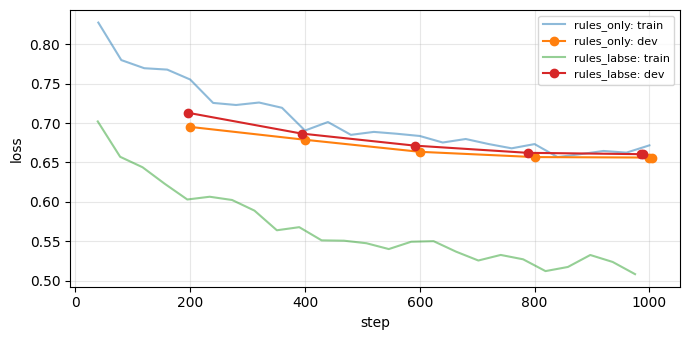

In [60]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, hist in TRAIN_LOGS.items():
    tr = [(x["step"], x["loss"]) for x in hist if "loss" in x]
    ev = [(x["step"], x["eval_loss"]) for x in hist if "eval_loss" in x]
    if tr: ax.plot(*zip(*tr), alpha=.5, label=f"{name}: train")
    if ev: ax.plot(*zip(*ev), "o-", label=f"{name}: dev")
ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.grid(alpha=.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/loss_curves.png", dpi=120); plt.show()

## 11. Results and the ablation verdict

BLEU                       chrF++            \
test_set               iitb_test in22_conv in22_gen iitb_test in22_conv   
system                                                                    
nllb600M_reference         23.74     24.13    25.05     49.35     45.81   
qwen_3shot_baseline         4.98      6.80     6.16     25.27     26.14   
qwen_qlora_rules_only       9.61     12.06    10.78     32.01     32.77   
qwen_qlora_rules_labse     10.95     13.14    12.32     34.25     34.48   

                                num_match                     
test_set               in22_gen iitb_test in22_conv in22_gen  
system                                                        
nllb600M_reference        50.94      99.2      96.7     98.1  
qwen_3shot_baseline       25.82      70.2      80.0     71.6  
qwen_qlora_rules_only     33.33      87.6      90.0     89.7  
qwen_qlora_rules_labse    35.89      91.5      91.7     92.5

Fine-tuned vs 3-shot baseline: {'BLEU': {'iitb_test': 5.97, 'in22_conv': 6.34, 'in22_gen': 6.16}, 'chrF++': {'iitb_test': 8.98, 'in22_conv': 8.34, 'in22_gen': 10.07}}
Effect of LaBSE filtering (rules+LaBSE minus rules-only): {'BLEU': {'iitb_test': 1.34, 'in22_conv': 1.08, 'in22_gen': 1.54}, 'chrF++': {'iitb_test': 2.24, 'in22_conv': 1.71, 'in22_gen': 2.56}}
Read this honestly: differences under about 0.5 BLEU on ~1,000 sentences are within noise. A null result is still a finding; one published study saw QE filtering help NMT models but not fine-tuned LLMs.


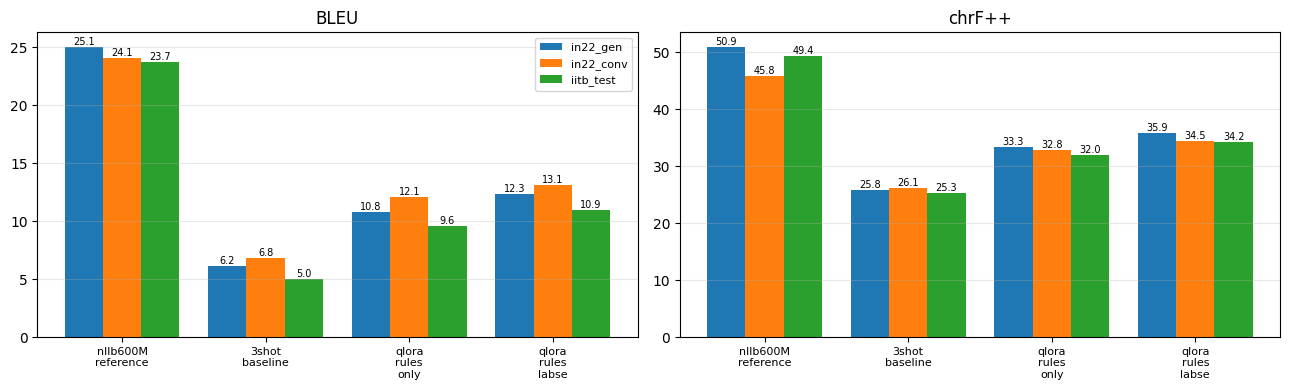

In [61]:
res = pd.DataFrame(RESULTS)
ORDER = [s for s in ["nllb600M_reference", "qwen_3shot_baseline", "qwen_qlora_rules_only", "qwen_qlora_rules_labse"]
         if s in res.system.unique()]
table = res.pivot(index="system", columns="test_set", values=["BLEU", "chrF++", "num_match"]).loc[ORDER].round(2)
display(table)

def delta(a, b, metric):
    r = res.pivot(index="system", columns="test_set", values=metric)
    return (r.loc[a] - r.loc[b]).round(2).to_dict()

SUMMARY["gain_vs_3shot"] = {m: delta("qwen_qlora_rules_labse", "qwen_3shot_baseline", m) for m in ["BLEU", "chrF++"]}
print("Fine-tuned vs 3-shot baseline:", SUMMARY["gain_vs_3shot"])
if RUN_ABLATION:
    SUMMARY["labse_filter_effect"] = {m: delta("qwen_qlora_rules_labse", "qwen_qlora_rules_only", m) for m in ["BLEU", "chrF++"]}
    print("Effect of LaBSE filtering (rules+LaBSE minus rules-only):", SUMMARY["labse_filter_effect"])
    print("Read this honestly: differences under about 0.5 BLEU on ~1,000 sentences are within noise. "
          "A null result is still a finding; one published study saw QE filtering help NMT models but not fine-tuned LLMs.")

sets = list(test_sets)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["BLEU", "chrF++"]):
    w = 0.8 / len(sets)
    for i, ts in enumerate(sets):
        look = res[res.test_set == ts].set_index("system")[metric]
        bars = ax.bar(np.arange(len(ORDER)) + i * w, [look.get(s, np.nan) for s in ORDER], w, label=ts)
        ax.bar_label(bars, fmt="%.1f", fontsize=7)
    ax.set_xticks(np.arange(len(ORDER)) + w * (len(sets) - 1) / 2)
    ax.set_xticklabels([s.replace("qwen_", "").replace("_", "\n") for s in ORDER], fontsize=8)
    ax.set_title(metric); ax.grid(axis="y", alpha=.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/results_chart.png", dpi=130); plt.show()

## 12. Controllable numerals
Same sentences, same adapter, only the `Numerals:` tag changes. **Control accuracy** = share of outputs containing digits whose digits are all in the requested script.

In [62]:
digit_src = pd.concat(test_sets.values())
digit_src = digit_src[digit_src.en.str.contains(r"\d")].drop_duplicates("en").head(300)["en"].tolist()

def control_accuracy(hyps, want):
    ok = total = 0
    for h in hyps:
        has_ascii, has_dev = bool(re.search(r"[0-9]", h)), bool(re.search(r"[०-९]", h))
        if has_ascii or has_dev:
            total += 1
            ok += (has_dev and not has_ascii) if want == "native" else (has_ascii and not has_dev)
    return round(100 * ok / total, 1) if total else float("nan")

control = {}
if digit_src:
    for tag in ["international", "native"]:
        hyps = llm_translate(model, digit_src, num=tag)
        control[tag] = {"control_accuracy": control_accuracy(hyps, tag), "num_match": number_match(digit_src, hyps)}
        print(tag, control[tag], "\n   e.g.", digit_src[0], "→", hyps[0])
SUMMARY["numeral_control"] = {"sentences": len(digit_src), **control}
pd.DataFrame(control).T

translating:   0%|          | 0/10 [00:00<?, ?it/s]

international {'control_accuracy': 98.9, 'num_match': 92.4} 
   e.g. British women of good social standing were scarce; in 1785 surgeon John Stewart wrote to his brother from Cawnpore: "Many of the women here are mere adventuresses from Milliners shops on Ludgate Hill and some even from Covent Garden and Old Drury [well-known areas of prostitution in late 18th century London]. → अच्छी सामाजिक स्थिति की ब्रिटिश महिलाएं अत्यंत कम थीं; 1785 में चावंपोर से अपने भाई को लिखते सर्जन जॉन स्टेटर ने कहा था: ‘हमारे यहां बहुत से महिलाएं लुडगेट हिल पर मिलिनर्स दुकानों से आती हैं और कुछ भी चौंती गेट और ओल ड्रियर जैसे लंदन के बादल शताब्दी के लिए लोहपान के क्षेत्रों से आती है।


translating:   0%|          | 0/10 [00:00<?, ?it/s]

native {'control_accuracy': 98.6, 'num_match': 92.4} 
   e.g. British women of good social standing were scarce; in 1785 surgeon John Stewart wrote to his brother from Cawnpore: "Many of the women here are mere adventuresses from Milliners shops on Ludgate Hill and some even from Covent Garden and Old Drury [well-known areas of prostitution in late 18th century London]. → अच्छी सामाजिक स्थिति की ब्रिटिश महिलाएं अत्यंत कम थीं; १७८५ में चावंपोर से अपने भाई को लिखते सर्जन जॉन स्टेटर ने कहा था: ‘हमारे यहां बहुत से महिलाएं लुडगेट हिल पर मिलिनर्स दुकानों से आती हैं और कुछ भी उनके बाद चैंप्गेन और ओल्ड ड्रियर [लंदन के बादी दशक में लड़कियों के लिए जाने जाने वाले दोस्ती और दुर्लभ क्षेत्र] से आती ह


,control_accuracy,num_match
international,98.9,92.4
native,98.6,92.4


## 13. Quality-aware decoding
Greedy decoding returns one translation. Instead: produce several candidates (1 greedy + sampled ones) and choose with a rule that needs **no reference**:
* **MBR (chrF)**: pick the candidate that agrees most with the other candidates (Minimum Bayes Risk).
* **LaBSE-QE**: pick the candidate whose meaning is closest to the English source.

Both are scored against the references afterwards. The cost is roughly `N_CAND`× the generation time, so this runs on a subset.

In [63]:
if RUN_RERANK:
    sub = test_sets[MAIN_SET].head(RERANK_LIMIT)
    srcs, refs = sub["en"].tolist(), sub["hi"].tolist()
    t0 = time.time()
    greedy = [normalize(h) for h in llm_translate(model, srcs)]
    t_greedy = time.time() - t0

    t0 = time.time()
    cands = []
    for i in tqdm(range(0, len(srcs), 8), desc="sampling candidates"):
        chunk = srcs[i:i + 8]
        sampled = llm_generate(model, [PROMPT.format(num="international", en=s) for s in chunk],
                               n=N_CAND - 1, do_sample=True, temperature=0.8, top_p=0.95)
        for g, ss in zip(greedy[i:i + 8], sampled):
            uniq = list(dict.fromkeys([g] + [normalize(x) for x in ss if x.strip()]))
            cands.append(uniq)
    t_sample = time.time() - t0

    def pick_mbr(c):
        if len(c) < 3:
            return c[0]
        util = [np.mean([sacrebleu.sentence_chrf(h, [o], word_order=2).score for o in c if o is not h]) for h in c]
        return c[int(np.argmax(util))]

    flat = [h for c in cands for h in c]
    flat_src = [s for s, c in zip(srcs, cands) for _ in c]
    qe = labse_similarity(flat_src, flat)
    pick_qe, k = [], 0
    for c in cands:
        pick_qe.append(c[int(np.argmax(qe[k:k + len(c)]))]); k += len(c)

    rerank = pd.DataFrame([
        {"decoding": "greedy", **score(greedy, refs), "num_match": number_match(srcs, greedy), "relative_cost": 1.0},
        {"decoding": f"MBR-chrF ({N_CAND} cands)", **score([pick_mbr(c) for c in cands], refs),
         "num_match": number_match(srcs, [pick_mbr(c) for c in cands]), "relative_cost": round(1 + t_sample / t_greedy, 1)},
        {"decoding": f"LaBSE-QE ({N_CAND} cands)", **score(pick_qe, refs),
         "num_match": number_match(srcs, pick_qe), "relative_cost": round(1 + t_sample / t_greedy, 1)},
    ])
    rerank.to_csv(f"{OUT_DIR}/decoding_experiment.csv", index=False)
    SUMMARY["decoding"] = {"test_set": MAIN_SET, "sentences": len(srcs),
                           "avg_unique_candidates": round(float(np.mean([len(c) for c in cands])), 2),
                           "rows": rerank.to_dict("records")}
    display(rerank)

translating:   0%|          | 0/10 [00:00<?, ?it/s]

sampling candidates:   0%|          | 0/38 [00:00<?, ?it/s]

embedding:   0%|          | 0/8 [00:00<?, ?it/s]

embedding:   0%|          | 0/8 [00:00<?, ?it/s]

,decoding,BLEU,chrF++,num_match,relative_cost
0,greedy,12.09,35.65,91.8,1.0
1,MBR-chrF (6 cands),12.20,36.21,93.4,6.5
2,LaBSE-QE (6 cands),11.82,35.60,92.9,6.5


## 14. Error analysis: fine-tuned model vs 3-shot baseline
Sentence-level chrF++ difference. Read the biggest regressions by hand: named entities, numbers, long sentences, formal vs colloquial wording. These become the "findings" section of your README and your interview answers.

In [64]:
a, b = PREDS[("qwen_3shot_baseline", MAIN_SET)], PREDS[("qwen_qlora_rules_labse", MAIN_SET)]
ea = pd.DataFrame({"en": b["en"], "ref": b["ref"], "before": a["hyp"], "after": b["hyp"],
                   "chrf_before": [sacrebleu.sentence_chrf(h, [r], word_order=2).score for h, r in zip(a["hyp"], a["ref"])],
                   "chrf_after":  [sacrebleu.sentence_chrf(h, [r], word_order=2).score for h, r in zip(b["hyp"], b["ref"])]})
ea["gain"] = ea.chrf_after - ea.chrf_before
ea["src_words"] = ea.en.str.split().str.len()
SUMMARY["error_analysis"] = {"test_set": MAIN_SET, "improved_pct": round(100 * float((ea.gain > 0).mean()), 1),
                             "worse_pct": round(100 * float((ea.gain < 0).mean()), 1)}
print(SUMMARY["error_analysis"])

by_len = ea.groupby(pd.cut(ea.src_words, [0, 10, 20, 30, 1000], labels=["≤10", "11–20", "21–30", ">30"]), observed=True)[["chrf_before", "chrf_after"]].mean().round(1)
print("\nchrF++ by source length (words):"); display(by_len)

md = [f"# Error analysis ({MAIN_SET}): fine-tuned vs 3-shot baseline\n"]
for title, part in [("Biggest improvements", ea.nlargest(8, "gain")), ("Biggest regressions", ea.nsmallest(8, "gain"))]:
    md.append(f"\n## {title}\n")
    for r in part.itertuples():
        md.append(f"- **EN:** {r.en}\n  - REF: {r.ref}\n  - BEFORE ({r.chrf_before:.0f}): {r.before}\n  - AFTER ({r.chrf_after:.0f}): {r.after}\n")
open(f"{OUT_DIR}/error_analysis.md", "w", encoding="utf-8").write("\n".join(md))
display(ea.nsmallest(5, "gain")[["en", "ref", "after", "gain"]])

{'test_set': 'in22_gen', 'improved_pct': 84.4, 'worse_pct': 15.6}

chrF++ by source length (words):


,chrf_before,chrf_after
src_words,,
≤10,28.5,35.3
11–20,27.7,38.0
21–30,25.6,36.6
>30,26.0,34.5


,en,ref,after,gain
489,This sort of sublime forgiveness was not natural to my father.,इस प्रकार की उदात्त क्षमा मेरे पिता के लिए सहज नहीं थी।,इस तरह की उत्तम भरती अपने पिता के लिए प्राकृतिक नहीं थी।,-21.196286
200,"The Brahmasutra (also called Vedanta Sutra, composed in the 1st millennium BCE) accepted this in verse 1.1.4 and asserts the need for the Upanishadic teachi...","ब्रह्मसूत्र (जिसे वेदांत सूत्र भी कहा जाता है, प्रथम सहस्राब्दी ई.पू. में रचित) के पद 1.1.4 में इसे स्वीकार करते हुए उपनिषदीय शिक्षाओं को टुकड़ों में नहीं ब...","ब्रह्मसूत्र (भी वेदांत सूत्र कहलाता है, जो एक्सएनएक्सएनएक्सएन ईसीएम ईसीएम ईसीएक्स ईसीएक्स ईस्के ईस्के ईस्केड ईस्केड ईस्त ईस्त ईस्त एक्सएनएक्स ईस्त ईस्त विषय...",-20.435727
568,"Village courts, such as Lok Adalat (the people's court) or Nyaya panchayat (the justice of the villages), offer alternative dispute resolution.","ग्राम न्यायालय, जैसी कि लोक अदालत (लोगों की अदालत) या न्याय पंचायत (गांव का न्याय) वैकल्पिक विवाद समाधान प्रदान करते हैं।",गांव की अदालतें जैसे लोक अदालत या न्याय पंचायत आपात संबंधी विवादों का विकल्पी समाधान प्रदान करती हैं।,-18.716908
808,Tourism emerged as the largest global industry of the 20th century and is projected to grow even faster in the 21st century.,20वीं शताब्दी में पर्यटन सबसे बड़े वैश्विक उद्योग के रूप में उभरा और अनुमान है कि 21वीं शताब्दी में यह और तेजी से बढ़ेगा।,यह दशक के दौरान यात्रा विकसित हुई और यह दशक के दशक में भी अधिक तेजी से विकसित होने की आशा है।,-18.478895
931,The brothers were deeply attached to each other.,दोनों भाइयों एक-दूसरे से बहुत प्रेम करते थे।,दोस्तों के बीच गहन संबंध थे।,-16.728499


## 15. Staged inference pipeline (backbone of the web demo)
`translate_pipeline()` is a generator: it yields one event per **real** stage with a timestamp. A frontend step tracker just listens to these events and lights up the matching step. The last stages attach a per-sentence **confidence** (LaBSE similarity between source and output) and a number check, and flag sentences a human should review.

In [65]:
def translate_pipeline(text, numerals="international", min_confidence=0.75):
    t0 = time.time()
    def event(stage, **info):
        return {"stage": stage, "ms": int(1000 * (time.time() - t0)), **info}

    text = normalize(text)
    latin, deva = len(re.findall(r"[A-Za-z]", text)), len(re.findall(r"[ऀ-ॿ]", text))
    yield event("1_detect_language", looks_english=latin > deva, latin_chars=latin, devanagari_chars=deva)

    sents = [s for s in re.split(r"(?<=[.!?])\s+", text) if s]
    yield event("2_normalise_and_split", sentences=len(sents))

    n_tok = sum(len(tok(PROMPT.format(num=numerals, en=s), add_special_tokens=False)["input_ids"]) for s in sents)
    yield event("3_tokenise", prompt_tokens=n_tok)

    hyps = llm_translate(model, sents, num=numerals)
    yield event("4_translate", sentences=len(hyps))

    conf = labse_similarity(sents, hyps)
    nums_ok = [set(numbers(s)) <= set(numbers(h)) for s, h in zip(sents, hyps)]
    flagged = [i for i, (c, ok) in enumerate(zip(conf, nums_ok)) if c < min_confidence or not ok]
    yield event("5_quality_check", confidence=[round(float(c), 3) for c in conf], numbers_ok=nums_ok, flagged_sentences=flagged)

    yield event("6_done", translation=" ".join(hyps))

sample_text = ("India launched 3 new satellites in 2025. The mission cost about 450 crore rupees. "
               "Scientists say the data will help farmers plan their crops better.")
for ev in translate_pipeline(sample_text, numerals="native"):
    print(json.dumps(ev, ensure_ascii=False))

{"stage": "1_detect_language", "ms": 0, "looks_english": true, "latin_chars": 113, "devanagari_chars": 0}
{"stage": "2_normalise_and_split", "ms": 0, "sentences": 3}
{"stage": "3_tokenise", "ms": 2, "prompt_tokens": 82}


translating:   0%|          | 0/1 [00:00<?, ?it/s]

{"stage": "4_translate", "ms": 8619, "sentences": 3}


embedding:   0%|          | 0/1 [00:00<?, ?it/s]

embedding:   0%|          | 0/1 [00:00<?, ?it/s]

{"stage": "5_quality_check", "ms": 8674, "confidence": [0.87, 0.82, 0.876], "numbers_ok": [true, true, true], "flagged_sentences": []}
{"stage": "6_done", "ms": 8674, "translation": "भारत ने २०२५ में ३ नये उपग्रहों का उपयोग किया। इस योजना का लागत लगभग ४५० करोड़ रुपये था। वैज्ञानिकों का कहना है कि इस डाटा से किसान अपने फसलों की योजना बेहतर बना सकेंगे।"}


## 16. Save everything
The adapter is a few tens of MB. To publish it, uncomment the push lines (needs a *write* token in `HF_TOKEN`).

In [66]:
FINAL_DIR = f"{OUT_DIR}/qwen3-1.7B-en-hi-qlora"
model.save_pretrained(FINAL_DIR); tok.save_pretrained(FINAL_DIR)
json.dump({"prompt_template": PROMPT, "numerals": ["international", "native"], "base_model": MODEL_ID},
          open(f"{FINAL_DIR}/prompt_config.json", "w"), indent=2)

SUMMARY["results"] = RESULTS
json.dump(SUMMARY, open(f"{OUT_DIR}/summary.json", "w"), indent=2, ensure_ascii=False, default=str)
print("README table:\n")
print(table.to_markdown())
print("\nsaved:", sorted(os.listdir(OUT_DIR)))

# model.push_to_hub("YOUR_HF_USERNAME/qwen3-1.7B-en-hi-qlora", token=HF_TOKEN)
# tok.push_to_hub("YOUR_HF_USERNAME/qwen3-1.7B-en-hi-qlora", token=HF_TOKEN)

README table:

| system                 |   ('BLEU', 'iitb_test') |   ('BLEU', 'in22_conv') |   ('BLEU', 'in22_gen') |   ('chrF++', 'iitb_test') |   ('chrF++', 'in22_conv') |   ('chrF++', 'in22_gen') |   ('num_match', 'iitb_test') |   ('num_match', 'in22_conv') |   ('num_match', 'in22_gen') |
|:-----------------------|------------------------:|------------------------:|-----------------------:|--------------------------:|--------------------------:|-------------------------:|-----------------------------:|-----------------------------:|----------------------------:|
| nllb600M_reference     |                   23.74 |                   24.13 |                  25.05 |                     49.35 |                     45.81 |                    50.94 |                         99.2 |                         96.7 |                        98.1 |
| qwen_3shot_baseline    |                    4.98 |                    6.8  |                   6.16 |                     25.27 |                 

## 17. COMET (optional, runs last)
COMET is the neural metric MT teams trust most, but its package needs older library versions than this notebook uses. So it runs in a **separate environment and process**. Everything above is already saved; if this cell fails, nothing is lost. Scores are added to `final_results.csv`.

In [67]:
COMET_SCRIPT = r'''
import sys, glob, os, re
import pandas as pd, torch
from comet import download_model, load_from_checkpoint
out = sys.argv[1]
model = load_from_checkpoint(download_model("Unbabel/wmt22-comet-da"))
rows = []
for f in sorted(glob.glob(os.path.join(out, "preds__*.csv"))):
    m = re.match(r"preds__(.+)__(.+)\.csv", os.path.basename(f))
    df = pd.read_csv(f, keep_default_na=False)
    data = [{"src": s, "mt": h, "ref": r} for s, h, r in zip(df["en"], df["hyp"], df["ref"])]
    res = model.predict(data, batch_size=64, gpus=1 if torch.cuda.is_available() else 0, progress_bar=False)
    rows.append({"system": m.group(1), "test_set": m.group(2), "COMET": round(100 * res.system_score, 2)})
    print(rows[-1], flush=True)
pd.DataFrame(rows).to_csv(os.path.join(out, "comet_scores.csv"), index=False)
'''

if RUN_COMET:
    try:
        del model; free_gpu()
        env_dir = "/tmp/comet_env"
        try:
            subprocess.run([sys.executable, "-m", "venv", "--system-site-packages", env_dir], check=True)
        except Exception:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "virtualenv"], check=True)
            subprocess.run([sys.executable, "-m", "virtualenv", "--system-site-packages", env_dir], check=True)
        subprocess.run([f"{env_dir}/bin/python", "-m", "pip", "install", "-q", "unbabel-comet"], check=True)
        open(f"{OUT_DIR}/comet_score.py", "w").write(COMET_SCRIPT)
        subprocess.run([f"{env_dir}/bin/python", f"{OUT_DIR}/comet_score.py", OUT_DIR], check=True)
        comet = pd.read_csv(f"{OUT_DIR}/comet_scores.csv")
        final = pd.DataFrame(RESULTS).merge(comet, on=["system", "test_set"], how="left")
        final.to_csv(f"{OUT_DIR}/final_results.csv", index=False)
        display(final.pivot(index="system", columns="test_set", values=["BLEU", "chrF++", "COMET"]).loc[ORDER].round(2))
    except Exception as e:
        print("COMET step did not complete; BLEU / chrF++ results above are unaffected.\n", repr(e)[:500])

Error: Command '['/tmp/comet_env/bin/python3', '-m', 'ensurepip', '--upgrade', '--default-pip']' returned non-zero exit status 1.


created virtual environment CPython3.13.16.final.0-64-x86_64 in 438ms
  creator CPython3Posix(dest=/tmp/comet_env, clear=False, no_vcs_ignore=False, venv_redirect=None, global=True)
  seeder FromAppData(download=False, pip=bundle, via=copy, app_data_dir=/root/.cache/virtualenv)
    added seed packages: entmax==1.3, huggingface_hub==0.36.2, jsonargparse==3.13.1, numpy==1.26.4, pip==26.3, protobuf==4.25.9, tokenizers==0.22.2, torchmetrics==0.10.3, transformers==4.57.6, unbabel_comet==2.2.7
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator,XonshActivator


/tmp/comet_env/lib/python3.13/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
Traceback (most recent call last):
  File "/kaggle/working/comet_score.py", line 4, in <module>
    from comet import download_model, load_from_checkpoint
  File "/tmp/comet_env/lib/python3.13/site-packages/comet/__init__.py", line 19, in <module>
    from .models import load_from_checkpoint, download_model
  File "/tmp/comet_env/lib/python3.13/site-packages/comet/models/__init__.py", line 24, in <module>
    from .base import CometModel
  File "/tmp/comet_env/lib/python3.13/site-packages/comet/models/base.py", line 29, in <module>
    import pytorch_lightning as ptl
  File "/usr/local/lib/python3.13/d

COMET step did not complete; BLEU / chrF++ results above are unaffected.
 CalledProcessError(1, ['/tmp/comet_env/bin/python', '/kaggle/working/comet_score.py', '/kaggle/working'])
